# Error Analysis — Standalone

Notebook này **chỉ load `best.pt` có sẵn**, không train lại. Dùng để phân tích failure mode của model trên val set.

**Yêu cầu**:
- `best.pt` đã tồn tại (tự tìm theo thứ tự ưu tiên)
- Dataset đã merge ở `data/merged/`
- Env `vehicle_env` (đã có ultralytics, opencv, pandas, matplotlib)

**Output**: `results/error_analysis/` — predictions pickle, metadata pickle, top worst CSV, charts.

**Thời gian chạy lần đầu**: ~8-10 phút (inference 14k val images). Lần sau: ~5s (dùng cache).

## 1. Setup

In [1]:
import os, sys, json, pickle, cv2
from pathlib import Path
from collections import Counter as CCounter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import ultralytics
from ultralytics import YOLO

print(f"Torch       : {torch.__version__}")
print(f"CUDA        : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU         : {torch.cuda.get_device_name(0)}")
print(f"Ultralytics : {ultralytics.__version__}")

Torch       : 2.5.1+cu124
CUDA        : True
GPU         : NVIDIA RTX 3500 Ada Generation Laptop GPU
Ultralytics : 8.4.142


In [2]:
# Paths — tự chuyển cwd về project root
PROJECT_ROOT = Path("/home/xuand/vn_traffic_ai").resolve()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

DATA_YAML   = PROJECT_ROOT / "data" / "data.yaml"
MERGED_DIR  = PROJECT_ROOT / "data" / "merged"
WEIGHTS_DIR = PROJECT_ROOT / "weights"
RUNS_DIR    = PROJECT_ROOT / "runs" / "detect"

VAL_IMG_DIR = MERGED_DIR / "images" / "val"
VAL_LBL_DIR = MERGED_DIR / "labels" / "val"

ERR_DIR = PROJECT_ROOT / "results" / "error_analysis"
ERR_DIR.mkdir(parents=True, exist_ok=True)

class_names = ["motorcycle", "car", "bus", "truck"]

# Chọn weights theo thứ tự ưu tiên (model mới nhất trước)
CANDIDATE_WEIGHTS = [
    RUNS_DIR / "train_v8s_1round_merged_v2" / "weights" / "best.pt",
    RUNS_DIR / "train_v8s_1round_merged"    / "weights" / "best.pt",
    RUNS_DIR / "runs" / "detect" / "train_v8s_ft_vnv3" / "weights" / "best.pt",
    WEIGHTS_DIR / "best.pt",
]
ANALYZE_WEIGHTS = next((w for w in CANDIDATE_WEIGHTS if w.exists()), None)
assert ANALYZE_WEIGHTS, f"Không tìm thấy best.pt trong: {CANDIDATE_WEIGHTS}"

VAL_IMAGES = sorted([p for p in VAL_IMG_DIR.iterdir()
                     if p.suffix.lower() in (".jpg",".jpeg",".png")])

print(f"[WEIGHTS] {ANALYZE_WEIGHTS}")
print(f"[VAL]     {len(VAL_IMAGES):,} images in {VAL_IMG_DIR}")
assert len(VAL_IMAGES) > 0, "Val set rỗng — kiểm tra lại data/merged/images/val"
assert VAL_LBL_DIR.exists(), f"Thiếu labels dir: {VAL_LBL_DIR}"
print(f"[LABELS]  {VAL_LBL_DIR}")

[WEIGHTS] /home/xuand/vn_traffic_ai/runs/detect/train_v8s_1round_merged_v2/weights/best.pt
[VAL]     14,344 images in /home/xuand/vn_traffic_ai/data/merged/images/val
[LABELS]  /home/xuand/vn_traffic_ai/data/merged/labels/val


## 2. Inference trên toàn val set (cache ra pickle)

Lần đầu mất ~5-8 phút. Lần sau tải cache instant.

In [3]:
PRED_CACHE = ERR_DIR / f"predictions_{ANALYZE_WEIGHTS.parent.parent.name}.pkl"

if PRED_CACHE.exists():
    print(f"[CACHE HIT] {PRED_CACHE}")
    with open(PRED_CACHE, "rb") as f:
        predictions = pickle.load(f)
else:
    print(f"[CACHE MISS] Running inference ...")
    model = YOLO(str(ANALYZE_WEIGHTS))
    predictions = {}
    BATCH = 64

    for i in tqdm(range(0, len(VAL_IMAGES), BATCH), desc="Inference"):
        batch_paths = VAL_IMAGES[i:i+BATCH]
        results = model.predict(
            [str(p) for p in batch_paths],
            imgsz=512, conf=0.001, iou=0.5,
            verbose=False, half=True
        )
        for p, r in zip(batch_paths, results):
            boxes = []
            if r.boxes is not None and len(r.boxes) > 0:
                xyxy = r.boxes.xyxy.cpu().numpy()
                cls  = r.boxes.cls.cpu().numpy().astype(int)
                conf = r.boxes.conf.cpu().numpy()
                for b, c, cf in zip(xyxy, cls, conf):
                    boxes.append({"xyxy": b.tolist(), "cls": int(c), "conf": float(cf)})
            predictions[p.name] = boxes

    with open(PRED_CACHE, "wb") as f:
        pickle.dump(predictions, f)
    print(f"[SAVED] {PRED_CACHE}")

n_pred = sum(len(v) for v in predictions.values())
print(f"\nImages with preds: {len(predictions):,}")
print(f"Total pred boxes : {n_pred:,}")

[CACHE MISS] Running inference ...


Inference:   0%|          | 0/225 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

## 3. Đọc GT labels + metadata (brightness, density, source)

Lần đầu ~2 phút (phải decode từng ảnh để đo brightness).

In [4]:
META_CACHE = ERR_DIR / "image_metadata.pkl"

def classify_source(name):
    for p in ("cantho", "detrac", "vnv3"):
        if name.startswith(p + "_"):
            return p
    return "unknown"

def read_yolo_gt(lbl_path, img_w, img_h):
    boxes = []
    if not lbl_path.exists():
        return boxes
    for line in lbl_path.read_text().splitlines():
        parts = line.split()
        if len(parts) < 5:
            continue
        cls = int(parts[0])
        xc, yc, w, h = map(float, parts[1:5])
        x1 = (xc - w/2) * img_w
        y1 = (yc - h/2) * img_h
        x2 = (xc + w/2) * img_w
        y2 = (yc + h/2) * img_h
        boxes.append({"xyxy": [x1, y1, x2, y2], "cls": cls})
    return boxes

if META_CACHE.exists():
    print(f"[CACHE HIT] {META_CACHE}")
    with open(META_CACHE, "rb") as f:
        image_meta, gt_data = pickle.load(f)
else:
    print(f"[CACHE MISS] Reading GT + metadata ...")
    image_meta = {}
    gt_data = {}

    for img_path in tqdm(VAL_IMAGES, desc="Meta"):
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        h, w = img.shape[:2]
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        brightness = float(hsv[:, :, 2].mean())

        lbl_path = VAL_LBL_DIR / (img_path.stem + ".txt")
        gts = read_yolo_gt(lbl_path, w, h)

        image_meta[img_path.name] = {
            "source": classify_source(img_path.name),
            "brightness": brightness,
            "n_gt": len(gts),
            "w": w, "h": h,
        }
        gt_data[img_path.name] = gts

    with open(META_CACHE, "wb") as f:
        pickle.dump((image_meta, gt_data), f)
    print(f"[SAVED] {META_CACHE}")

df_meta = pd.DataFrame.from_dict(image_meta, orient="index")
print(f"\nTotal images: {len(df_meta):,}")
print("\nSource:")
print(df_meta["source"].value_counts())
print("\nBrightness distribution:")
print(df_meta["brightness"].describe().round(1))
print(f"\nTotal GT boxes: {df_meta['n_gt'].sum():,}")

[CACHE MISS] Reading GT + metadata ...


Meta:   0%|          | 0/14344 [00:00<?, ?it/s]

[SAVED] /home/xuand/vn_traffic_ai/results/error_analysis/image_metadata.pkl

Total images: 14,344

Source:
source
detrac    14128
cantho      216
Name: count, dtype: int64

Brightness distribution:
count    14344.0
mean       120.2
std          8.5
min         76.4
25%        116.1
50%        121.7
75%        125.9
max        147.5
Name: brightness, dtype: float64

Total GT boxes: 103,085


## 4. Match pred ↔ GT, phân loại TP/FP/FN

In [5]:
CONF_THRESHOLD = 0.25
IOU_THRESHOLD  = 0.5

def iou_xyxy(b1, b2):
    x1 = max(b1[0], b2[0]); y1 = max(b1[1], b2[1])
    x2 = min(b1[2], b2[2]); y2 = min(b1[3], b2[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    a1 = (b1[2]-b1[0]) * (b1[3]-b1[1])
    a2 = (b2[2]-b2[0]) * (b2[3]-b2[1])
    return inter / (a1 + a2 - inter + 1e-9)

def box_size_coco(xyxy):
    area = (xyxy[2]-xyxy[0]) * (xyxy[3]-xyxy[1])
    if area < 32*32: return "small"
    if area < 96*96: return "medium"
    return "large"

def match_image(preds, gts, conf_thresh=CONF_THRESHOLD, iou_thresh=IOU_THRESHOLD):
    preds_f = [p for p in preds if p["conf"] >= conf_thresh]
    preds_sorted = sorted(enumerate(preds_f), key=lambda x: -x[1]["conf"])

    gt_matched = [False] * len(gts)
    pred_tp    = [False] * len(preds_f)
    pred_cc    = [False] * len(preds_f)

    for pi, p in preds_sorted:
        best_iou = iou_thresh
        best_gi  = -1
        for gi, g in enumerate(gts):
            if gt_matched[gi]:
                continue
            io = iou_xyxy(p["xyxy"], g["xyxy"])
            if io >= best_iou:
                best_iou = io
                best_gi  = gi
        if best_gi >= 0:
            gt_matched[best_gi] = True
            if gts[best_gi]["cls"] == p["cls"]:
                pred_tp[pi] = True
            else:
                pred_cc[pi] = True

    fp_boxes = [{"pred": preds_f[pi],
                 "reason": "class_confused" if pred_cc[pi] else "no_gt"}
                for pi in range(len(preds_f)) if not pred_tp[pi]]
    fn_boxes = [gts[gi] for gi in range(len(gts)) if not gt_matched[gi]]
    tp_boxes = [preds_f[pi] for pi in range(len(preds_f)) if pred_tp[pi]]

    return {
        "n_pred": len(preds_f),
        "n_gt":   len(gts),
        "n_tp":   sum(pred_tp),
        "n_fp":   sum(1 for pi in range(len(preds_f)) if not pred_tp[pi] and not pred_cc[pi]),
        "n_class_confused": sum(pred_cc),
        "n_fn":   len(fn_boxes),
        "tp_boxes": tp_boxes,
        "fp_boxes": fp_boxes,
        "fn_boxes": fn_boxes,
    }

print(f"Matching @ conf>={CONF_THRESHOLD}, IoU>={IOU_THRESHOLD} ...")
match_results = {}
for name in tqdm(gt_data.keys()):
    preds = predictions.get(name, [])
    gts   = gt_data[name]
    match_results[name] = match_image(preds, gts)

total_tp = sum(m["n_tp"] for m in match_results.values())
total_fp = sum(m["n_fp"] for m in match_results.values())
total_fn = sum(m["n_fn"] for m in match_results.values())
total_cc = sum(m["n_class_confused"] for m in match_results.values())
total_gt = sum(m["n_gt"] for m in match_results.values())

prec = total_tp / max(total_tp + total_fp + total_cc, 1)
rec  = total_tp / max(total_gt, 1)
print(f"\n[OVERALL]")
print(f"  TP = {total_tp:,}")
print(f"  FP (no GT)          = {total_fp:,}")
print(f"  FP (class confused) = {total_cc:,}")
print(f"  FN (missed GT)      = {total_fn:,}")
print(f"  Precision = {prec:.3f}")
print(f"  Recall    = {rec:.3f}")

Matching @ conf>=0.25, IoU>=0.5 ...


  0%|          | 0/14344 [00:00<?, ?it/s]


[OVERALL]
  TP = 84,315
  FP (no GT)          = 13,966
  FP (class confused) = 3,347
  FN (missed GT)      = 15,423
  Precision = 0.830
  Recall    = 0.818


## 5. Breakdown FN/FP theo 6 chiều

In [6]:
# Flat tables cho FN và FP
fn_rows = []
for name, m in match_results.items():
    meta = image_meta.get(name, {})
    for gt_box in m["fn_boxes"]:
        fn_rows.append({
            "image": name,
            "source": meta.get("source", "unknown"),
            "brightness": meta.get("brightness", 0),
            "n_gt_in_image": meta.get("n_gt", 0),
            "gt_class": class_names[gt_box["cls"]],
            "size_bucket": box_size_coco(gt_box["xyxy"]),
        })
df_fn = pd.DataFrame(fn_rows)

fp_rows = []
for name, m in match_results.items():
    meta = image_meta.get(name, {})
    for fp_box in m["fp_boxes"]:
        p = fp_box["pred"]
        fp_rows.append({
            "image": name,
            "source": meta.get("source", "unknown"),
            "brightness": meta.get("brightness", 0),
            "pred_class": class_names[p["cls"]],
            "conf": p["conf"],
            "size_bucket": box_size_coco(p["xyxy"]),
            "reason": fp_box["reason"],
        })
df_fp = pd.DataFrame(fp_rows)

print(f"FN rows: {len(df_fn):,}   FP rows: {len(df_fp):,}")

def pct_table(df, group_cols, total_label):
    tbl = df.groupby(group_cols).size().reset_index(name="count")
    tbl["pct"] = (100 * tbl["count"] / tbl["count"].sum()).round(2)
    tbl = tbl.sort_values("count", ascending=False)
    print(f"\n--- {total_label}: tổng {tbl['count'].sum():,} ---")
    print(tbl.to_string(index=False))
    return tbl

tbl_fn_class  = pct_table(df_fn, ["gt_class"],   "FN by CLASS")
tbl_fn_size   = pct_table(df_fn, ["size_bucket"], "FN by SIZE")
tbl_fn_source = pct_table(df_fn, ["source"],     "FN by SOURCE")
tbl_fp_class  = pct_table(df_fp, ["pred_class"], "FP by CLASS")
tbl_fp_reason = pct_table(df_fp, ["reason"],     "FP by REASON")

FN rows: 15,423   FP rows: 17,313

--- FN by CLASS: tổng 15,423 ---
  gt_class  count   pct
       car  13504 87.56
     truck   1690 10.96
       bus    195  1.26
motorcycle     34  0.22

--- FN by SIZE: tổng 15,423 ---
size_bucket  count   pct
      small  13178 85.44
     medium   2080 13.49
      large    165  1.07

--- FN by SOURCE: tổng 15,423 ---
source  count   pct
detrac  15378 99.71
cantho     45  0.29

--- FP by CLASS: tổng 17,313 ---
pred_class  count   pct
       car  13946 80.55
     truck   2938 16.97
       bus    251  1.45
motorcycle    178  1.03

--- FP by REASON: tổng 17,313 ---
        reason  count   pct
         no_gt  13966 80.67
class_confused   3347 19.33


## 6. Chart 6 chiều

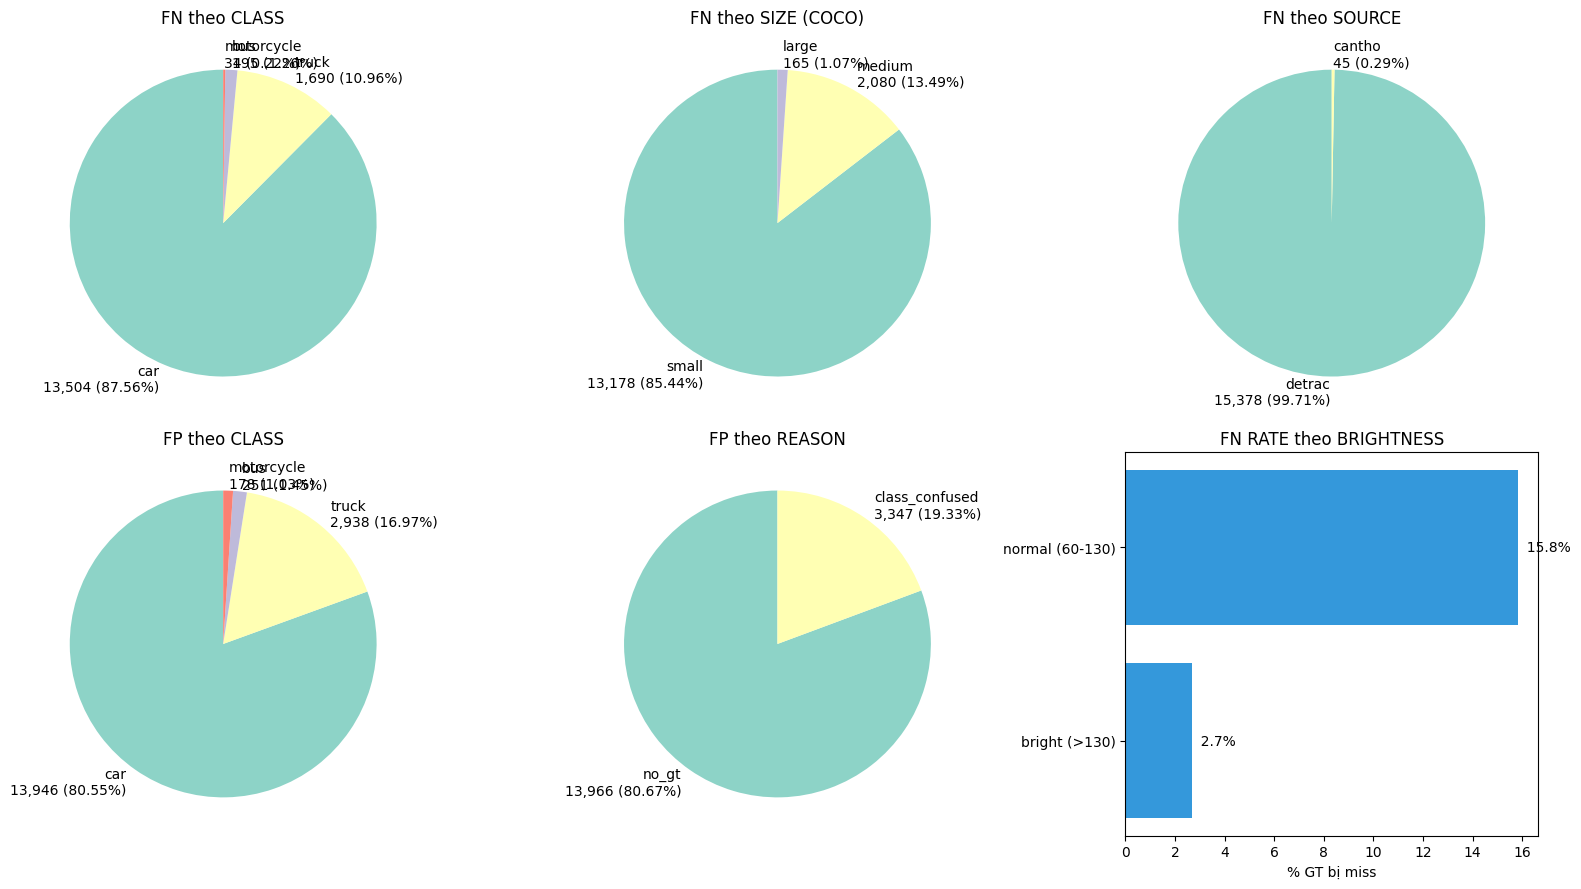

[SAVED] /home/xuand/vn_traffic_ai/results/error_analysis/chart_6dim.png


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

def draw_pie(ax, tbl, label_col, title):
    sizes = tbl["count"].values
    labels = [f"{r[label_col]}\n{r['count']:,} ({r['pct']}%)" for _, r in tbl.iterrows()]
    ax.pie(sizes, labels=labels, startangle=90, colors=plt.cm.Set3.colors)
    ax.set_title(title)

draw_pie(axes[0,0], tbl_fn_class,   "gt_class",     "FN theo CLASS")
draw_pie(axes[0,1], tbl_fn_size,    "size_bucket",  "FN theo SIZE (COCO)")
draw_pie(axes[0,2], tbl_fn_source,  "source",       "FN theo SOURCE")
draw_pie(axes[1,0], tbl_fp_class,   "pred_class",   "FP theo CLASS")
draw_pie(axes[1,1], tbl_fp_reason,  "reason",       "FP theo REASON")

# Brightness → FN rate
def brightness_bucket(b):
    if b < 60: return "dark (<60)"
    if b < 130: return "normal (60-130)"
    return "bright (>130)"

df_meta_copy = df_meta.copy()
df_meta_copy["b_bucket"] = df_meta_copy["brightness"].apply(brightness_bucket)
df_fn_b = df_fn.copy()
df_fn_b["b_bucket"] = df_fn_b["brightness"].apply(brightness_bucket)

gt_per_bucket = df_meta_copy.groupby("b_bucket")["n_gt"].sum()
fn_per_bucket = df_fn_b.groupby("b_bucket").size()
fn_rate = (fn_per_bucket / gt_per_bucket * 100).fillna(0).reset_index()
fn_rate.columns = ["b_bucket", "fn_rate_pct"]
fn_rate = fn_rate.sort_values("fn_rate_pct", ascending=True)

ax = axes[1,2]
ax.barh(fn_rate["b_bucket"], fn_rate["fn_rate_pct"], color="#3498db")
for i, v in enumerate(fn_rate["fn_rate_pct"]):
    ax.text(v, i, f"  {v:.1f}%", va="center", fontsize=10)
ax.set_title("FN RATE theo BRIGHTNESS")
ax.set_xlabel("% GT bị miss")

plt.tight_layout()
plt.savefig(ERR_DIR / "chart_6dim.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"[SAVED] {ERR_DIR / 'chart_6dim.png'}")

## 7. Cross-condition: class × size và class × source

=== FN rate: class × size ===
                           gt     fn  fn_rate_%
gt_class   size_bucket                         
bus        small            8      8      100.0
truck      small         1874   1468       78.3
car        small        21359  11671       54.6
bus        medium         754    175       23.2
motorcycle small          359     31        8.6
car        medium       49443   1696        3.4
truck      medium        6634    206        3.1
motorcycle medium         248      3        1.2
car        large        17463    137        0.8
bus        large         1663     12        0.7
truck      large         3280     16        0.5

=== FN rate: class × source ===
                      gt       fn  fn_rate_%
gt_class   source                           
car        detrac  87651  13493.0       15.4
truck      detrac  11750   1690.0       14.4
bus        detrac   2419    195.0        8.1
motorcycle cantho    607     34.0        5.6
car        cantho    614     11.0        1.

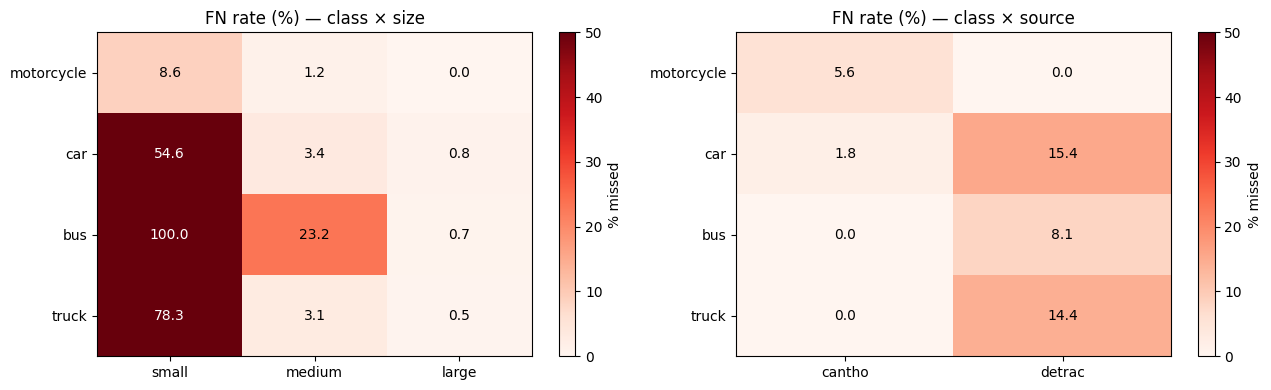

[SAVED] /home/xuand/vn_traffic_ai/results/error_analysis/chart_cross.png


In [8]:
gt_rows = []
for name, gts in gt_data.items():
    meta = image_meta.get(name, {})
    for g in gts:
        gt_rows.append({
            "image": name,
            "source": meta.get("source", "unknown"),
            "gt_class": class_names[g["cls"]],
            "size_bucket": box_size_coco(g["xyxy"]),
        })
df_gt = pd.DataFrame(gt_rows)

def xtab_rate(df_fn, df_gt, group_cols):
    gt_cnt = df_gt.groupby(group_cols).size().rename("gt")
    fn_cnt = df_fn.groupby(group_cols).size().rename("fn")
    merged = pd.concat([gt_cnt, fn_cnt], axis=1).fillna(0)
    merged["fn_rate_%"] = (100 * merged["fn"] / merged["gt"]).round(1)
    return merged.sort_values("fn_rate_%", ascending=False)

print("=== FN rate: class × size ===")
tbl_cs = xtab_rate(df_fn, df_gt, ["gt_class", "size_bucket"])
print(tbl_cs.to_string())

print("\n=== FN rate: class × source ===")
tbl_cz = xtab_rate(df_fn, df_gt, ["gt_class", "source"])
print(tbl_cz.to_string())

# Heatmaps
pivot1 = tbl_cs["fn_rate_%"].unstack(fill_value=0)
pivot1 = pivot1.reindex(index=class_names, columns=["small","medium","large"], fill_value=0)

pivot2 = tbl_cz["fn_rate_%"].unstack(fill_value=0)
pivot2 = pivot2.reindex(index=class_names, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, pivot, title in [(axes[0], pivot1, "FN rate (%) — class × size"),
                          (axes[1], pivot2, "FN rate (%) — class × source")]:
    im = ax.imshow(pivot.values, cmap="Reds", aspect="auto", vmin=0, vmax=50)
    ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index)
    ax.set_title(title)
    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            v = pivot.values[i,j]
            ax.text(j, i, f"{v:.1f}", ha="center", va="center",
                    color="white" if v > 25 else "black", fontsize=10)
    fig.colorbar(im, ax=ax, label="% missed")

plt.tight_layout()
plt.savefig(ERR_DIR / "chart_cross.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"[SAVED] {ERR_DIR / 'chart_cross.png'}")

## 8. Top-20 ảnh WORST — visualize GT (xanh) + FP (đỏ)

[SAVED] /home/xuand/vn_traffic_ai/results/error_analysis/top_worst_images.csv

Top-20 worst:
                        image  error_count  n_gt  n_fn  n_fp  n_cc source  brightness
detrac_MVI_20064_img00442.jpg           21    17    11     9     1 detrac       122.7
detrac_MVI_20064_img00443.jpg           21    17    11     9     1 detrac       123.0
detrac_MVI_20064_img00612.jpg           17    23    12     4     1 detrac       122.5
detrac_MVI_20064_img00622.jpg           16    24    13     3     0 detrac       121.8
detrac_MVI_20064_img00616.jpg           16    24    12     3     1 detrac       122.2
detrac_MVI_20064_img00799.jpg           16    20    13     2     1 detrac       122.3
detrac_MVI_20064_img00617.jpg           15    24    12     3     0 detrac       122.0
detrac_MVI_20064_img00762.jpg           15    22    12     2     1 detrac       123.2
detrac_MVI_20064_img00610.jpg           15    23    11     3     1 detrac       122.7
detrac_MVI_20064_img00615.jpg           15    2

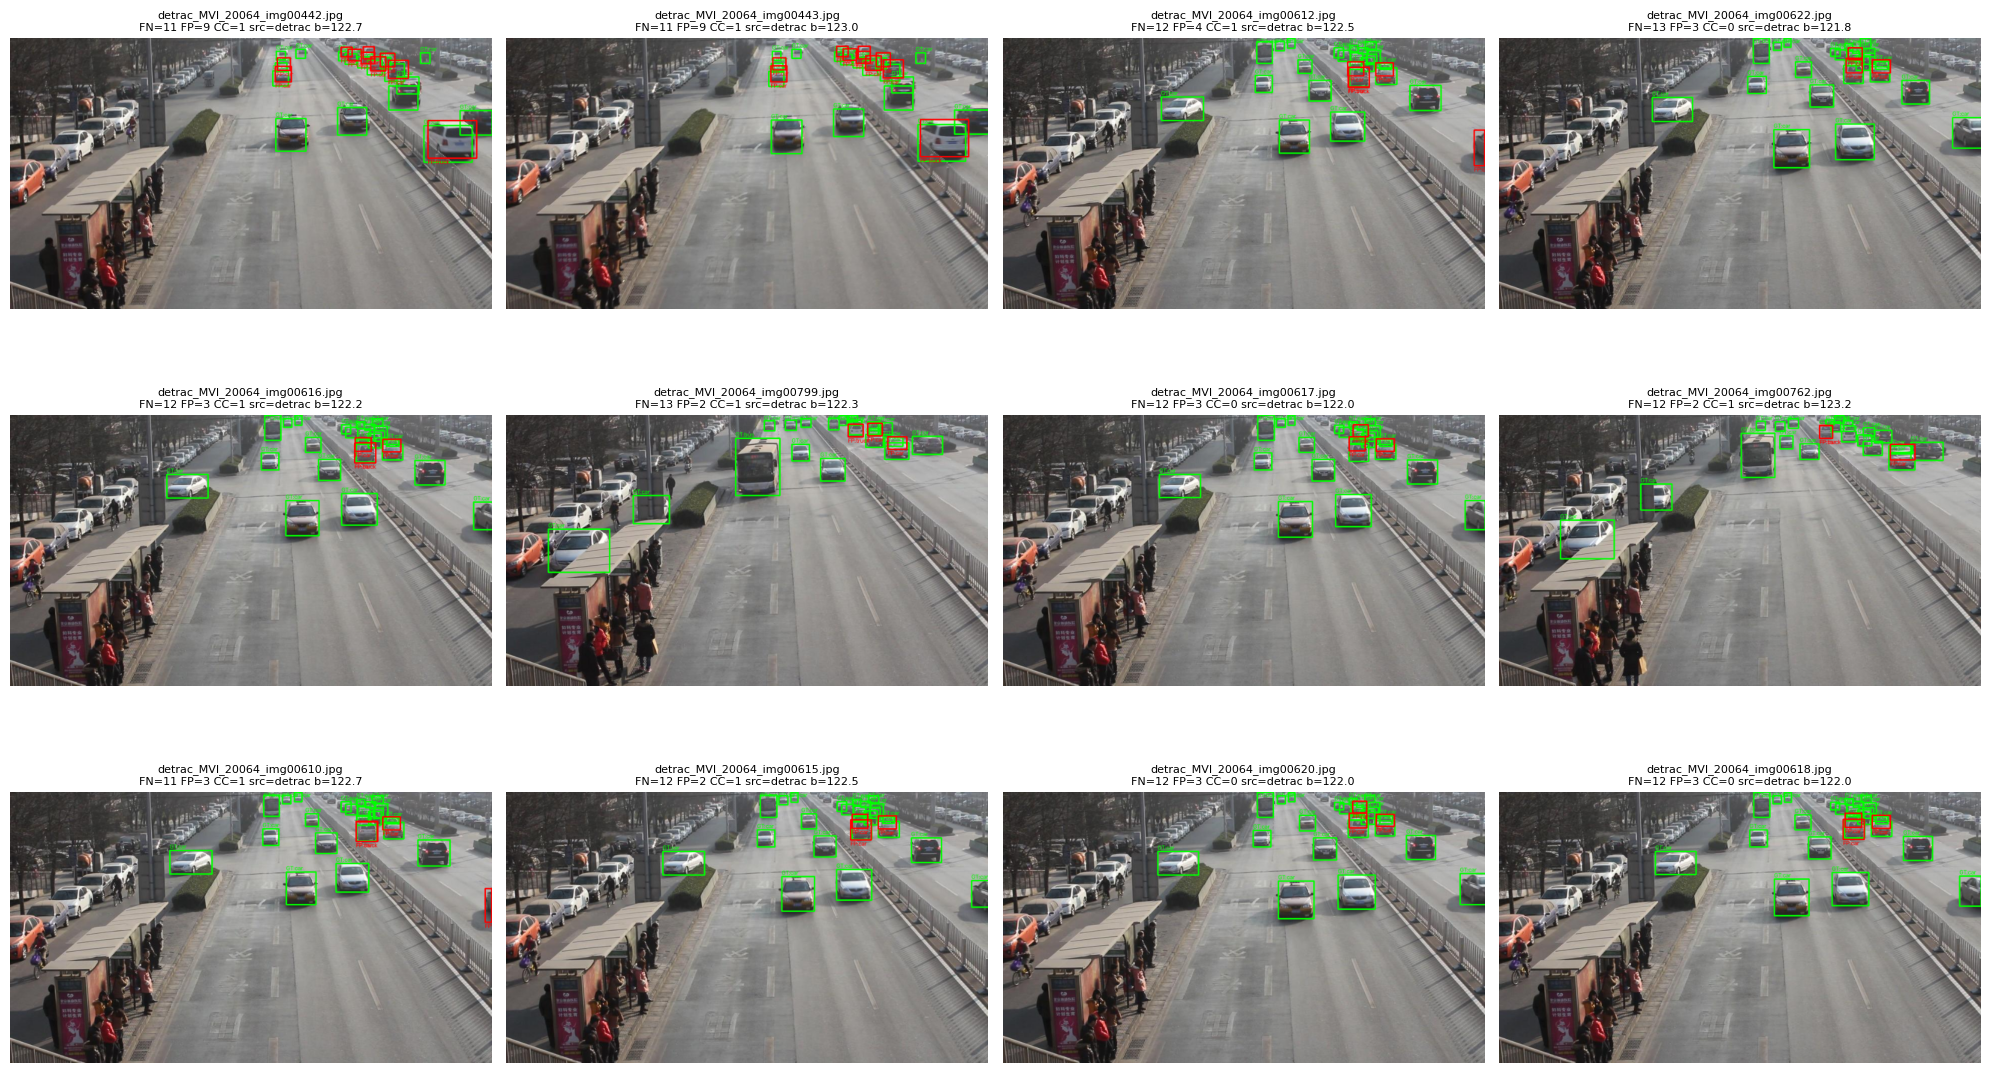

[SAVED] /home/xuand/vn_traffic_ai/results/error_analysis/worst_images.png


In [9]:
worst_rows = []
for name, m in match_results.items():
    worst_rows.append({
        "image": name,
        "error_count": m["n_fn"] + m["n_fp"] + m["n_class_confused"],
        "n_gt": m["n_gt"],
        "n_fn": m["n_fn"],
        "n_fp": m["n_fp"],
        "n_cc": m["n_class_confused"],
        "source": image_meta.get(name, {}).get("source", "?"),
        "brightness": round(image_meta.get(name, {}).get("brightness", 0), 1),
    })
df_worst = pd.DataFrame(worst_rows).sort_values("error_count", ascending=False).head(50)

WORST_CSV = ERR_DIR / "top_worst_images.csv"
df_worst.to_csv(WORST_CSV, index=False)
print(f"[SAVED] {WORST_CSV}")
print("\nTop-20 worst:")
print(df_worst.head(20).to_string(index=False))

# Visualize 12 ảnh đầu
TOP_N = 12
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
axes = axes.flatten()

for ax, (_, row) in zip(axes, df_worst.head(TOP_N).iterrows()):
    name = row["image"]
    img = cv2.imread(str(VAL_IMG_DIR / name))
    if img is None:
        ax.set_visible(False); continue
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    m = match_results[name]
    # GT boxes (xanh)
    for g in gt_data[name]:
        x1,y1,x2,y2 = map(int, g["xyxy"])
        cv2.rectangle(img, (x1,y1), (x2,y2), (0,255,0), 2)
        cv2.putText(img, f"GT:{class_names[g['cls']]}", (x1, max(y1-3, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0,255,0), 1)
    # FP boxes (đỏ)
    for fp in m["fp_boxes"]:
        p = fp["pred"]
        x1,y1,x2,y2 = map(int, p["xyxy"])
        cv2.rectangle(img, (x1,y1), (x2,y2), (255,0,0), 2)
        cv2.putText(img, f"FP:{class_names[p['cls']]}", (x1, y2+12),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255,0,0), 1)
    h, w = img.shape[:2]
    if max(h,w) > 800:
        scale = 800 / max(h,w)
        img = cv2.resize(img, (int(w*scale), int(h*scale)))
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"{name[:35]}\nFN={row['n_fn']} FP={row['n_fp']} CC={row['n_cc']} "
                 f"src={row['source']} b={row['brightness']}", fontsize=8)

plt.tight_layout()
plt.savefig(ERR_DIR / "worst_images.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"[SAVED] {ERR_DIR / 'worst_images.png'}")

## 9. Export cho Tuần 2

File `top_worst_images.csv` đã lưu. Mở bằng Excel/LibreOffice, thêm cột `manual_reason`, xem lần lượt 50 ảnh ở `data/merged/images/val/<image_name>`, phân loại lý do fail theo 5-6 nhóm:
- occlusion (bị che)
- lighting (quá tối / quá sáng)
- small (object nhỏ)
- crowded (nhiều object chồng)
- class_ambiguity (van vs truck, bike vs motorcycle)
- label_noise (GT sai)

Sau đó group lại thành pie chart error taxonomy → viết hypothesis cho Tuần 3.

In [10]:
# Summary mini-report + export
summary = {
    "weights": str(ANALYZE_WEIGHTS.relative_to(PROJECT_ROOT)),
    "val_images": len(VAL_IMAGES),
    "total_gt": int(total_gt),
    "total_tp": int(total_tp),
    "total_fp": int(total_fp),
    "total_fn": int(total_fn),
    "total_class_confused": int(total_cc),
    "precision": round(prec, 4),
    "recall":    round(rec, 4),
    "fn_by_class":  tbl_fn_class.set_index("gt_class")["count"].to_dict(),
    "fn_by_size":   tbl_fn_size.set_index("size_bucket")["count"].to_dict(),
    "fn_by_source": tbl_fn_source.set_index("source")["count"].to_dict(),
    "fp_by_class":  tbl_fp_class.set_index("pred_class")["count"].to_dict(),
    "fp_by_reason": tbl_fp_reason.set_index("reason")["count"].to_dict(),
}

SUMMARY_JSON = ERR_DIR / "summary.json"
SUMMARY_JSON.write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(f"[SAVED] {SUMMARY_JSON}")
print(json.dumps(summary, indent=2, ensure_ascii=False))

[SAVED] /home/xuand/vn_traffic_ai/results/error_analysis/summary.json
{
  "weights": "runs/detect/train_v8s_1round_merged_v2/weights/best.pt",
  "val_images": 14344,
  "total_gt": 103085,
  "total_tp": 84315,
  "total_fp": 13966,
  "total_fn": 15423,
  "total_class_confused": 3347,
  "precision": 0.8296,
  "recall": 0.8179,
  "fn_by_class": {
    "car": 13504,
    "truck": 1690,
    "bus": 195,
    "motorcycle": 34
  },
  "fn_by_size": {
    "small": 13178,
    "medium": 2080,
    "large": 165
  },
  "fn_by_source": {
    "detrac": 15378,
    "cantho": 45
  },
  "fp_by_class": {
    "car": 13946,
    "truck": 2938,
    "bus": 251,
    "motorcycle": 178
  },
  "fp_by_reason": {
    "no_gt": 13966,
    "class_confused": 3347
  }
}
